# Dynamic Model in Levels

**EmbeddingGemma 2 version** of `main/code/04_evaluation.ipynb`: the fine-tuned (DoubleMLDeep) product embeddings are replaced by [EmbeddingGemma 2](https://huggingface.co/google/embeddinggemma-2) embeddings (text + image, Matryoshka 256 dimensions). Datasets are read from `gemma/data`, raw data from `main/data`, outputs are written to `gemma/outputs`.

Apart from the parameters below, the check of the estimation sample (cell writing `main_*_keys.csv` in `main/code`) and the export of the key results at the end, the notebook is identical to `main/code/04_evaluation.ipynb`.

In [1]:
# Parameters (default: EmbeddingGemma 2 text + image embeddings, 256 dimensions)
data_dir = "../data"  # "../../main/data": fine-tuned embeddings as in main/code/04_evaluation.ipynb
txt_only = True  # True: text-only embeddings (datasets from 01_2_create_dataset_txt.ipynb)
emb_dim = 256  # Matryoshka dimension of the EmbeddingGemma 2 embeddings: 256 | 768 (text + image only)
output_dir = '../outputs/04_evaluation_comparison/gemma_txt_dim256'

In [2]:
import os
import datasets
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from lightgbm import LGBMRegressor
from sklearn.metrics import r2_score

import doubleml as dml

from utils.utils_data2 import (
    get_cis,
    generate_basis,
    generate_interactions,
)

from utils.utils_models import (
    iv_model,
    lin_model,
    lin_model_cate,
    summarize_lin_model,
    summarize_dml,
    chi2_test,
    predict_cate,
)
import warnings
warnings.filterwarnings("ignore")

# Get a colorblind-friendly palette
palette = sns.color_palette("colorblind")

confidence_level = 0.9
ci_level_name, ci_names = get_cis(confidence_level)

Path(output_dir).mkdir(parents=True, exist_ok=True)

Confidence Level: 90.0%


In [3]:
include_embeddings = True
dataframe_name = f"dataset_txt_only_{txt_only}_embeddings_{include_embeddings}"
if emb_dim != 256:
    dataframe_name += f"_dim{emb_dim}"
df_full_train = pd.read_csv(f"{data_dir}/{dataframe_name}_train.zip")
df_full_val = pd.read_csv(f"{data_dir}/{dataframe_name}_val.zip")

columns_to_drop = [
    "Q_t-2",
    "P_bb_t-2",
    "REVIEW_COUNT_t-2",
    "RATING_t-2",
    "pred_ml_l_lag_1",
    "pred_ml_m_lag_1",
]


df_full_train = df_full_train.drop(columns=columns_to_drop)
df_full_val = df_full_val.drop(columns=columns_to_drop)

df_full_train = df_full_train.dropna()
df_full_val = df_full_val.dropna()

dummy_subcat_names = [
    category for category in df_full_val["subcat_aggregated"].unique()
]
all_time_steps = sorted([str(date) for date in df_full_val["date"].unique()])

print(f"Dummy subcat names: {dummy_subcat_names}")
print(f"All time steps: {all_time_steps}")
df_full_val.columns

Dummy subcat names: ['Residual', 'Cars & Race Cars', 'Trains & Trams', 'Train Sets', 'Trucks', 'Tractors', 'Race Tracks', 'Airplanes', 'Motor Vehicles', 'Vehicle Playsets', 'Skateboards']
All time steps: ['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22', '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11', '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01', '2024-01-29']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'REVIEW_COUNT_t-1', 'RATING_t-1', 'Delta_Q_t', 'Delta_P_bb_t',
       'pred_ml_l', 'pred_ml_m', 'pred_ml_l_diff', 'pred_ml_m_diff',
       'pred_ml_l_diff_lag_1', 'pred_ml_m_diff_lag_1'],
      dtype='object', length=342)

In [4]:
print(dataframe_name)

dataset_txt_only_True_embeddings_True


In [5]:
print(df_full_val.shape)
print(df_full_train.shape)

(38041, 342)
(38146, 342)


In [6]:
# same estimation sample as in the main analysis (keys written by main/code/04_evaluation.ipynb)
assert df_full_val[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("../../main/code/main_val_keys.csv"))
assert df_full_train[["ASIN", "date"]].reset_index(drop=True).equals(pd.read_csv("../../main/code/main_train_keys.csv"))

In [7]:
df_full_val.isna().sum()

ASIN                    0
date                    0
index                   0
Q_t                     0
PRICE                   0
                       ..
pred_ml_m               0
pred_ml_l_diff          0
pred_ml_m_diff          0
pred_ml_l_diff_lag_1    0
pred_ml_m_diff_lag_1    0
Length: 342, dtype: int64

In [8]:
df_full_train["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [9]:
df_full_val["date"].unique()

array(['2023-02-27', '2023-03-27', '2023-04-24', '2023-05-22',
       '2023-06-19', '2023-07-17', '2023-08-14', '2023-09-11',
       '2023-10-09', '2023-11-06', '2023-12-04', '2024-01-01',
       '2024-01-29'], dtype=object)

In [10]:
df_full_train["ASIN"].nunique()

3717

In [11]:
df_full_val["ASIN"].nunique()

3708

In [12]:
from datetime import datetime

date_objects = [datetime.strptime(date, "%Y-%m-%d") for date in all_time_steps]

# Calculate the difference in days between consecutive dates
date_differences = [
    (date_objects[i + 1] - date_objects[i]).days for i in range(len(date_objects) - 1)
]

# Print the differences
print(date_differences)

[28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28, 28]


## Variable Names

In [13]:
n_lags = 1

outcome = ["Q_t"]
base_treatment = ["P_bb_t"]
lag_1_vars = ["Q_t-1", "P_bb_t-1"]

dummy_time_steps = all_time_steps[n_lags:]

all_dummy_controls = (
    dummy_subcat_names
    + dummy_time_steps
    + [
        "Lightning Deals: Upcoming Deal",
        "Buy Box: Is FBA",
    ]
)
dummy_baselines = [dummy_time_steps[0], "Residual"]
dummy_time_steps_wo_baseline = [t for t in dummy_time_steps if t not in dummy_baselines]
dummy_controls = [t for t in all_dummy_controls if t not in dummy_baselines]

cont_controls = [
    "RATING_t-1",
    "REVIEW_COUNT_t-1",
    "New Offer Count: Current",
    "Count of retrieved live offers: New, FBA",
    "Count of retrieved live offers: New, FBM",
]

add_controls_to_scale = [
    "RATING",
    "REVIEW_COUNT",
]

controls_pca = ["pca_0", "pca_1", "pca_2", "pca_3", "pca_4"]
controls_similarities = [
    "similarity_cluster_0",
    "similarity_cluster_1",
    "similarity_cluster_2",
    "similarity_cluster_3",
    "similarity_cluster_4",
]

embeddings = [f"emb_{i}" for i in range(emb_dim)]
assert set(embeddings) == {c for c in df_full_val.columns if c.startswith("emb_")}

controls_to_scale = cont_controls + add_controls_to_scale

additional_controls = cont_controls + dummy_controls

## Interactions & CATE Basis

In [14]:
basis_vars = controls_similarities + lag_1_vars
df_basis, column_transformer, column_dict = generate_basis(
    df=df_full_val,
    cols_without_scaling=controls_similarities,
    cols_to_scale=lag_1_vars,
    degree=1,
)
df_basis.head()

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,0.023542,-0.110367,-0.00207,-0.13044,0.155107
1,1.0,0.272505,0.653600,0.023542,-0.110367,-0.00207,-0.13044,0.155107
2,1.0,0.036240,0.687961,0.023542,-0.110367,-0.00207,-0.13044,0.155107
3,1.0,0.025283,0.636881,0.023542,-0.110367,-0.00207,-0.13044,0.155107
4,1.0,-0.051370,0.556816,0.023542,-0.110367,-0.00207,-0.13044,0.155107


In [15]:
df_interact_val, interaction_vars = generate_interactions(
    df=df_full_val, df_basis=df_basis, cols_to_interact=["Q_t-1", "P_bb_t-1"]
)

print(f"Interactions: {interaction_vars}")
df_interact_val.columns

Interactions: ['interaction_Q_t-1_intercept', 'interaction_Q_t-1_Q_t-1', 'interaction_Q_t-1_P_bb_t-1', 'interaction_Q_t-1_similarity_cluster_0', 'interaction_Q_t-1_similarity_cluster_1', 'interaction_Q_t-1_similarity_cluster_2', 'interaction_Q_t-1_similarity_cluster_3', 'interaction_Q_t-1_similarity_cluster_4', 'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1', 'interaction_P_bb_t-1_P_bb_t-1', 'interaction_P_bb_t-1_similarity_cluster_0', 'interaction_P_bb_t-1_similarity_cluster_1', 'interaction_P_bb_t-1_similarity_cluster_2', 'interaction_P_bb_t-1_similarity_cluster_3', 'interaction_P_bb_t-1_similarity_cluster_4']


Index(['ASIN', 'date', 'index', 'Q_t', 'PRICE', 'P_bb_t', 'text', 'window',
       'REVIEW_COUNT', 'RATING',
       ...
       'interaction_Q_t-1_similarity_cluster_3',
       'interaction_Q_t-1_similarity_cluster_4',
       'interaction_P_bb_t-1_intercept', 'interaction_P_bb_t-1_Q_t-1',
       'interaction_P_bb_t-1_P_bb_t-1',
       'interaction_P_bb_t-1_similarity_cluster_0',
       'interaction_P_bb_t-1_similarity_cluster_1',
       'interaction_P_bb_t-1_similarity_cluster_2',
       'interaction_P_bb_t-1_similarity_cluster_3',
       'interaction_P_bb_t-1_similarity_cluster_4'],
      dtype='object', length=358)

## Average Effect

In [16]:
df_dynamic = df_interact_val.copy()

### Linear Models

In [17]:
def estimate_linear_model(controls):
    model = lin_model(
        df=df_dynamic,
        outcome=outcome,
        treatments=base_treatment,
        controls=controls,
        level=confidence_level,
        cov_type="cluster",
        cov_kwds={"groups": df_dynamic["ASIN"]},
    )
    return model

In [18]:
estimate_linear_model(controls=[])

Adjusted R^2: 0.0027
          coef  std err        t  P>|t|   [5.0%  95.0%]
const  -10.756    0.104 -103.858  0.000 -10.926 -10.586
P_bb_t  -0.111    0.033   -3.384  0.001  -0.164  -0.057


,lower,upper,coef
P_bb_t,-0.164462,-0.056884,-0.110673


In [19]:
estimate_linear_model(controls=embeddings)

Adjusted R^2: 0.3718
           coef  std err       t  P>|t|   [5.0%  95.0%]
const   -10.017    0.123 -81.339  0.000 -10.220  -9.815
P_bb_t   -0.373    0.040  -9.321  0.000  -0.439  -0.307
emb_0    -0.104    0.529  -0.196  0.845  -0.974   0.766
emb_1    -0.015    0.552  -0.027  0.978  -0.923   0.893
emb_2     0.498    0.551   0.903  0.366  -0.409   1.405
...         ...      ...     ...    ...     ...     ...
emb_251   0.120    0.509   0.235  0.814  -0.718   0.957
emb_252  -0.962    0.578  -1.666  0.096  -1.912  -0.012
emb_253  -0.951    0.502  -1.894  0.058  -1.776  -0.125
emb_254  -0.764    0.565  -1.352  0.176  -1.694   0.166
emb_255  -1.531    0.598  -2.561  0.010  -2.515  -0.548

[258 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.438989,-0.307294,-0.373141


In [20]:
estimate_linear_model(controls=additional_controls)

Adjusted R^2: 0.2213
                                            coef  std err       t  P>|t|  \
const                                    -11.961    0.233 -51.298  0.000   
P_bb_t                                    -0.225    0.031  -7.254  0.000   
RATING_t-1                                 0.222    0.047   4.710  0.000   
REVIEW_COUNT_t-1                           0.000    0.000   5.015  0.000   
New Offer Count: Current                  -0.015    0.006  -2.599  0.009   
Count of retrieved live offers: New, FBA   0.056    0.013   4.217  0.000   
Count of retrieved live offers: New, FBM  -0.033    0.008  -4.285  0.000   
Cars & Race Cars                           0.259    0.057   4.513  0.000   
Trains & Trams                             0.456    0.131   3.473  0.001   
Train Sets                                 0.422    0.077   5.454  0.000   
Trucks                                     0.464    0.064   7.291  0.000   
Tractors                                   0.399    0.131   3.042  

,lower,upper,coef
P_bb_t,-0.275748,-0.173807,-0.224778


In [21]:
estimate_linear_model(controls=additional_controls + embeddings)

Adjusted R^2: 0.469
                            coef  std err       t  P>|t|   [5.0%  95.0%]
const                    -11.449    0.207 -55.395  0.000 -11.789 -11.109
P_bb_t                    -0.350    0.037  -9.475  0.000  -0.411  -0.290
RATING_t-1                 0.232    0.037   6.286  0.000   0.171   0.292
REVIEW_COUNT_t-1           0.000    0.000   5.338  0.000   0.000   0.000
New Offer Count: Current  -0.004    0.005  -0.844  0.399  -0.013   0.004
...                          ...      ...     ...    ...     ...     ...
emb_251                    0.233    0.465   0.501  0.616  -0.532   0.998
emb_252                   -0.652    0.504  -1.294  0.196  -1.482   0.177
emb_253                   -0.678    0.452  -1.501  0.133  -1.422   0.065
emb_254                   -0.291    0.517  -0.563  0.573  -1.142   0.560
emb_255                   -0.962    0.535  -1.799  0.072  -1.842  -0.083

[286 rows x 6 columns]


,lower,upper,coef
P_bb_t,-0.411333,-0.28964,-0.350486


In [22]:
ci_linear_base_lagged = estimate_linear_model(controls=lag_1_vars)

Adjusted R^2: 0.8835
           coef  std err        t  P>|t|  [5.0%  95.0%]
const    -0.677    0.034  -19.935    0.0 -0.733  -0.621
P_bb_t   -0.690    0.040  -17.248    0.0 -0.756  -0.624
Q_t-1     0.936    0.003  321.411    0.0  0.931   0.941
P_bb_t-1  0.678    0.040   16.995    0.0  0.613   0.744


In [23]:
ci_linear_embeddings = estimate_linear_model(controls=lag_1_vars + embeddings)

Adjusted R^2: 0.8861
           coef  std err        t  P>|t|  [5.0%  95.0%]
const    -0.992    0.047  -21.266  0.000 -1.069  -0.915
P_bb_t   -0.679    0.040  -17.065  0.000 -0.745  -0.614
Q_t-1     0.898    0.004  209.758  0.000  0.891   0.905
P_bb_t-1  0.630    0.040   15.873  0.000  0.565   0.696
emb_0     0.043    0.072    0.593  0.553 -0.075   0.161
...         ...      ...      ...    ...    ...     ...
emb_251   0.007    0.069    0.101  0.919 -0.106   0.120
emb_252  -0.047    0.077   -0.610  0.542 -0.175   0.080
emb_253  -0.071    0.068   -1.045  0.296 -0.183   0.041
emb_254  -0.085    0.073   -1.156  0.248 -0.206   0.036
emb_255  -0.076    0.081   -0.928  0.354 -0.209   0.058

[260 rows x 6 columns]


In [24]:
ci_linear_base_lagged_add_controls = estimate_linear_model(
    controls=lag_1_vars + additional_controls
)

Adjusted R^2: 0.8929
                                           coef  std err        t  P>|t|  \
const                                    -0.962    0.051  -18.978  0.000   
P_bb_t                                   -0.746    0.039  -18.956  0.000   
Q_t-1                                     0.925    0.003  279.493  0.000   
P_bb_t-1                                  0.722    0.039   18.383  0.000   
RATING_t-1                                0.030    0.007    4.621  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    8.670  0.000   
New Offer Count: Current                 -0.001    0.001   -1.625  0.104   
Count of retrieved live offers: New, FBA  0.005    0.001    3.398  0.001   
Count of retrieved live offers: New, FBM -0.004    0.001   -3.797  0.000   
Cars & Race Cars                          0.020    0.006    3.371  0.001   
Trains & Trams                            0.052    0.014    3.754  0.000   
Train Sets                                0.032    0.008    4.069  

In [25]:
ci_linear_base_lagged_add_controls_emb = estimate_linear_model(
    controls=lag_1_vars + additional_controls + embeddings
)

Adjusted R^2: 0.895
             coef  std err        t  P>|t|  [5.0%  95.0%]
const      -1.299    0.065  -19.974  0.000 -1.406  -1.192
P_bb_t     -0.729    0.039  -18.600  0.000 -0.793  -0.664
Q_t-1       0.891    0.005  190.616  0.000  0.884   0.899
P_bb_t-1    0.680    0.039   17.363  0.000  0.616   0.744
RATING_t-1  0.039    0.008    5.012  0.000  0.026   0.051
...           ...      ...      ...    ...    ...     ...
emb_251     0.030    0.069    0.429  0.668 -0.084   0.143
emb_252    -0.042    0.075   -0.560  0.575 -0.165   0.081
emb_253    -0.042    0.065   -0.645  0.519 -0.150   0.065
emb_254    -0.052    0.073   -0.707  0.479 -0.172   0.069
emb_255    -0.036    0.079   -0.455  0.649 -0.167   0.094

[288 rows x 6 columns]


In [26]:
ci_linear_base_lagged_add_controls_sim = estimate_linear_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8936
                                           coef  std err        t  P>|t|  \
const                                    -1.111    0.056  -19.764  0.000   
P_bb_t                                   -0.734    0.039  -18.737  0.000   
Q_t-1                                     0.913    0.004  240.462  0.000   
P_bb_t-1                                  0.707    0.039   18.079  0.000   
similarity_cluster_0                      1.927    0.190   10.121  0.000   
similarity_cluster_1                      1.354    0.142    9.554  0.000   
similarity_cluster_2                      1.488    0.152    9.763  0.000   
similarity_cluster_3                      1.350    0.122   11.082  0.000   
similarity_cluster_4                      1.352    0.147    9.191  0.000   
RATING_t-1                                0.036    0.007    5.243  0.000   
REVIEW_COUNT_t-1                          0.000    0.000    9.266  0.000   
New Offer Count: Current                 -0.001    0.001   -1.824  

In [27]:
ci_linear_interactions = estimate_linear_model(
    controls=interaction_vars + controls_similarities + additional_controls
)

Adjusted R^2: 0.8939
                                            coef  std err       t  P>|t|  \
const                                     -1.535    0.351  -4.374  0.000   
P_bb_t                                    -0.736    0.039 -18.677  0.000   
interaction_Q_t-1_intercept                0.639    0.031  20.429  0.000   
interaction_Q_t-1_Q_t-1                   -0.010    0.004  -2.693  0.007   
interaction_Q_t-1_P_bb_t-1                -0.049    0.002 -22.977  0.000   
interaction_Q_t-1_similarity_cluster_0     0.271    0.243   1.118  0.263   
interaction_Q_t-1_similarity_cluster_1     0.170    0.186   0.913  0.361   
interaction_Q_t-1_similarity_cluster_2     0.202    0.202   1.000  0.317   
interaction_Q_t-1_similarity_cluster_3     0.178    0.151   1.178  0.239   
interaction_Q_t-1_similarity_cluster_4     0.159    0.177   0.899  0.369   
interaction_P_bb_t-1_intercept            -0.162    0.009 -18.025  0.000   
interaction_P_bb_t-1_Q_t-1                 0.085    0.009   9.269  

In [28]:
ci_linear_base_lagged["model"] = "Linear lagged"
ci_linear_embeddings["model"] = "Linear lagged_and_embeddings"
ci_linear_base_lagged_add_controls["model"] = "Linear lagged_and_add_controls"
ci_linear_base_lagged_add_controls_emb["model"] = (
    "Linear lagged_and_add_controls_and_emb"
)
ci_linear_base_lagged_add_controls_sim["model"] = (
    "Linear lagged_and_add_controls_and_sim"
)
ci_linear_interactions["model"] = "Linear interactions"

df_base = pd.concat(
    [
        ci_linear_base_lagged,
        ci_linear_embeddings,
        ci_linear_base_lagged_add_controls,
        ci_linear_base_lagged_add_controls_emb,
        ci_linear_base_lagged_add_controls_sim,
    ],
    ignore_index=True,
)

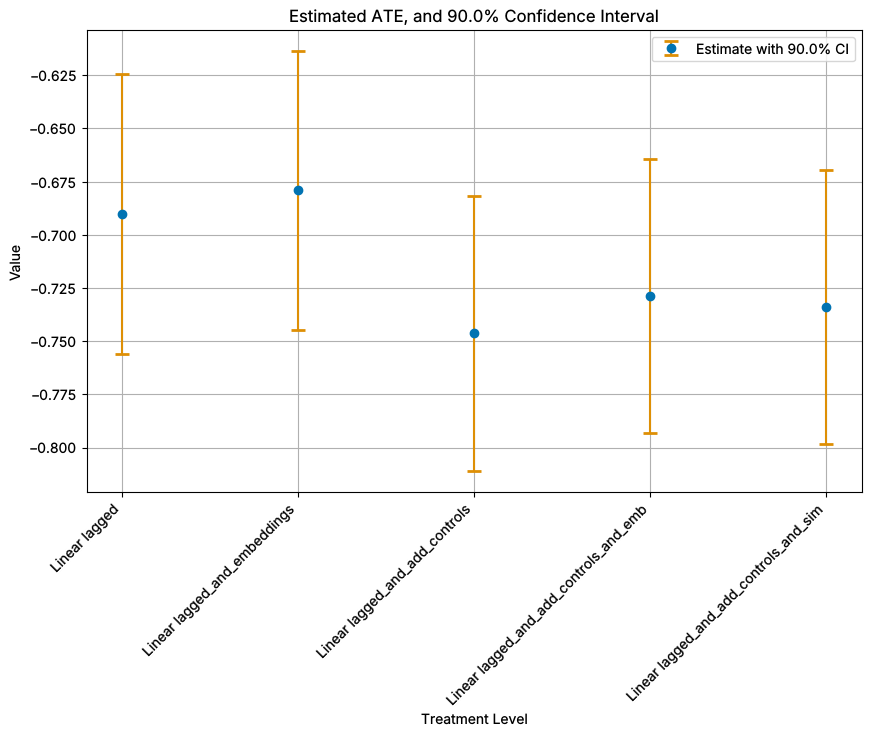

In [29]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_base["model"],
    df_base["coef"],
    yerr=[df_base["coef"] - df_base["lower"], df_base["upper"] - df_base["coef"]],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"linear_ate_estimates.png"))
plt.show()

In [30]:
df_base

,lower,upper,coef,model
0,-0.756093,-0.624438,-0.690266,Linear lagged
1,-0.744582,-0.613666,-0.679124,Linear lagged_and_embeddings
2,-0.811127,-0.681600,-0.746364,Linear lagged_and_add_controls
3,-0.793301,-0.664395,-0.728848,Linear lagged_and_add_controls_and_emb
4,-0.798128,-0.669311,-0.733719,Linear lagged_and_add_controls_and_sim


### DML Models

In [31]:
ml_g = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)
ml_m = LGBMRegressor(n_estimators=500, lr=0.02, random_state=42, verbose=-1)


def r2(y_true, y_pred):
    subset = np.logical_not(np.isnan(y_true))
    return r2_score(y_true[subset], y_pred[subset])


def estimate_dml_model(controls):
    tab_dml_data = dml.DoubleMLClusterData(
        df_dynamic,
        y_col=outcome[0],
        d_cols=base_treatment,
        x_cols=controls,
        cluster_cols="ASIN",
    )

    np.random.seed(3141)
    tab_dml_obj = dml.DoubleMLPLR(tab_dml_data, ml_g, ml_m)
    tab_dml_obj.fit()

    tab_summary_df = summarize_dml(tab_dml_obj, level=confidence_level)
    ci_tab_dml = tab_summary_df[ci_names + ["coef"]]
    ci_tab_dml.columns = ["lower", "upper", "coef"]

    r2_scores = tab_dml_obj.evaluate_learners(metric=r2)
    print(
        f"R2 Outcome: {round(r2_scores['ml_l'][0, 0], 4)} R2 Treatment: {round(r2_scores['ml_m'][0, 0], 4)}\n"
    )

    return tab_dml_obj, ci_tab_dml

In [32]:
tab_dml_obj_embeddings, ci_tab_dml_embeddings = estimate_dml_model(
    controls=lag_1_vars + embeddings
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.586     0.05 -11.794    0.0 -0.668 -0.505
R2 Outcome: 0.8723 R2 Treatment: 0.9722



In [33]:
tab_dml_obj_add_controls, ci_tab_dml_add_controls = estimate_dml_model(
    controls=lag_1_vars + additional_controls
)

        coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.69    0.041 -16.812    0.0 -0.758 -0.623
R2 Outcome: 0.8991 R2 Treatment: 0.9775



In [34]:
tab_dml_obj_embeddings_add_controls, ci_tab_dml_embeddings_add_controls = (
    estimate_dml_model(controls=lag_1_vars + embeddings + additional_controls)
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.636    0.048 -13.292    0.0 -0.714 -0.557
R2 Outcome: 0.8984 R2 Treatment: 0.9742



In [35]:
tab_dml_obj_sim_add_controls, ci_tab_dml_sim_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_similarities + additional_controls
)

         coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.677    0.039 -17.201    0.0 -0.742 -0.612
R2 Outcome: 0.8998 R2 Treatment: 0.9771



In [36]:
tab_dml_obj_pca_add_controls, ci_tab_dml_pca_add_controls = estimate_dml_model(
    controls=lag_1_vars + controls_pca + additional_controls
)

        coef  std err       t  P>|t|   5.0%  95.0%
P_bb_t -0.69    0.041 -16.762    0.0 -0.757 -0.622
R2 Outcome: 0.9016 R2 Treatment: 0.9773



### Visualization

In [37]:
ci_tab_dml_embeddings["model"] = "plr_embeddings"
ci_tab_dml_add_controls["model"] = "plr_add_controls"
ci_tab_dml_embeddings_add_controls["model"] = "plr_embeddings_add_controls"
ci_tab_dml_sim_add_controls["model"] = "plr_sim_add_controls"
ci_tab_dml_pca_add_controls["model"] = "plr_pca_add_controls"


df_averages = pd.concat(
    [
        ci_tab_dml_embeddings,
        ci_tab_dml_add_controls,
        ci_tab_dml_embeddings_add_controls,
        ci_tab_dml_sim_add_controls,
        ci_tab_dml_pca_add_controls,
    ],
    ignore_index=True,
)

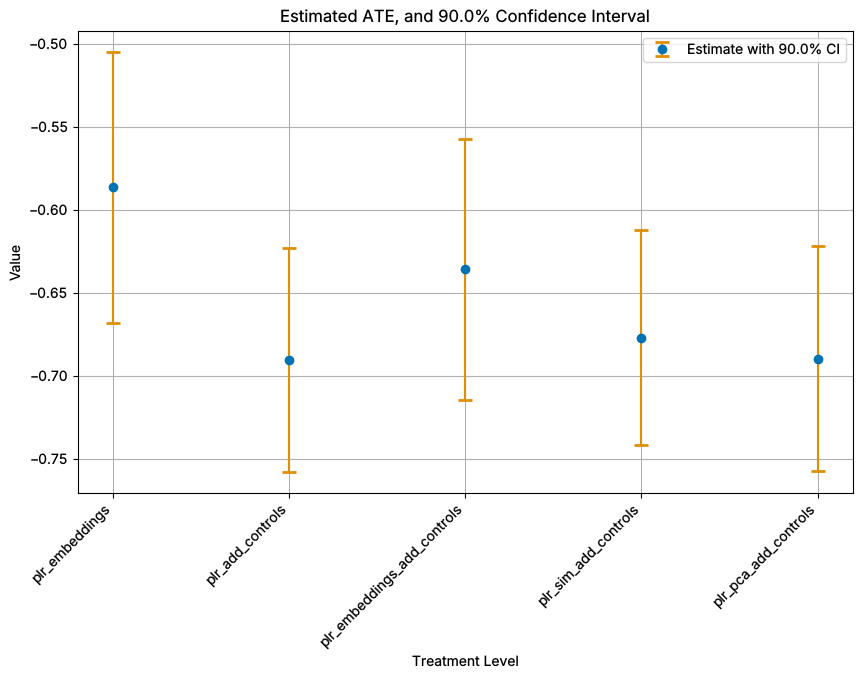

In [38]:
# Plotting
plt.figure(figsize=(10, 6))
# Plot Estimate with CI
plt.errorbar(
    df_averages["model"],
    df_averages["coef"],
    yerr=[
        df_averages["coef"] - df_averages["lower"],
        df_averages["upper"] - df_averages["coef"],
    ],
    fmt="o",
    capsize=5,
    capthick=2,
    ecolor=palette[1],
    color=palette[0],
    label=f"Estimate with {round(confidence_level * 100, 1)}% CI",
    zorder=2,
)

plt.title(f"Estimated ATE, and {round(confidence_level * 100, 1)}% Confidence Interval")
plt.xlabel("Treatment Level")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Value")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(output_dir, f"plr_ate_estimates.png"))
plt.show()

## GATEs

0
similarity_cluster_0    10937
similarity_cluster_1     6375
similarity_cluster_2     8613
similarity_cluster_3     8014
similarity_cluster_4     4102
dtype: int64


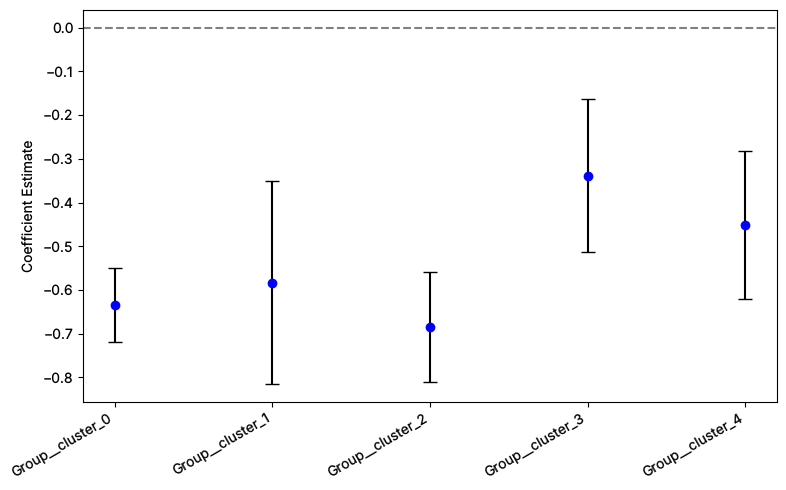

In [39]:
groups = pd.DataFrame(
    df_dynamic[
        [
            "similarity_cluster_0",
            "similarity_cluster_1",
            "similarity_cluster_2",
            "similarity_cluster_3",
            "similarity_cluster_4",
        ]
    ].idxmax(axis=1)
)

print(groups.groupby(0).size())
gates_0 = tab_dml_obj_embeddings.gate(groups)
gates_0_summ = gates_0.summary
gates_0_summ["err_lower"] = gates_0_summ["coef"] - gates_0_summ["[0.025"]
gates_0_summ["err_upper"] = gates_0_summ["0.975]"] - gates_0_summ["coef"]

# Positions on the x-axis
x_vals = range(len(gates_0_summ))

plt.figure(figsize=(8, 5))
plt.errorbar(
    x=x_vals,
    y=gates_0_summ["coef"],
    yerr=[gates_0_summ["err_lower"], gates_0_summ["err_upper"]],
    fmt="o",
    capsize=5,
    color="blue",
    ecolor="black",
)

# Draw a zero line for reference
plt.axhline(y=0, color="gray", linestyle="--")

# Customizing x-axis labels
plt.xticks(
    ticks=x_vals,
    labels=[gr.replace("similarity", "") for gr in gates_0_summ.index],
    rotation=30,
    ha="right",
)
plt.ylabel("Coefficient Estimate")
plt.tight_layout()
plt.show()

## CATEs

In [40]:
uniform_ci = True  # False | True

In [41]:
cate_controls = lag_1_vars + embeddings + additional_controls
cate_controls_interactions = cate_controls + interaction_vars

plr_obj = tab_dml_obj_embeddings_add_controls

In [42]:
import gc

gc.collect()

3456

In [43]:
cate_kwargs_val = {"cov_type": "cluster", "cov_kwds": {"groups": df_dynamic["ASIN"]}}

cate_models_polynomial = {
    "Linear Specification": None,
    "Linear Specification (Interactions)": None,
    "PLR Specification": None,
}

# Linear Models
cate_models_polynomial["Linear Specification"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls,
    **cate_kwargs_val,
)

print(f"\nLinear Specification")
df_specification_1 = summarize_lin_model(
    cate_models_polynomial["Linear Specification"], level=confidence_level
)
print("=" * 80)  #

cate_models_polynomial["Linear Specification (Interactions)"] = lin_model_cate(
    df=df_dynamic,
    outcome=outcome,
    basis=df_basis,
    treatment=base_treatment,
    controls=cate_controls_interactions,
    **cate_kwargs_val,
)

print(f"\nLinear specification with interactions")
df_specification_2 = summarize_lin_model(
    cate_models_polynomial["Linear Specification (Interactions)"],
    level=confidence_level,
)
print("=" * 80)

# tabular DML model
cate_models_polynomial["PLR Specification"] = plr_obj.cate(df_basis, **cate_kwargs_val)

print(f"\nTabular DML PLR Specification")
df_specification_3 = summarize_lin_model(
    cate_models_polynomial["PLR Specification"].blp_model, level=confidence_level
)
print("=" * 80)


Linear Specification
                       coef  std err       t  P>|t|    5.0%  95.0%
intercept            -0.730    0.041 -17.871  0.000  -0.798 -0.663
Q_t-1                -0.187    0.045  -4.177  0.000  -0.260 -0.113
P_bb_t-1             -0.020    0.036  -0.552  0.581  -0.079  0.039
similarity_cluster_0 -7.683    2.530  -3.037  0.002 -11.845 -3.522
similarity_cluster_1 -6.333    2.043  -3.100  0.002  -9.693 -2.973
similarity_cluster_2 -6.541    2.188  -2.989  0.003 -10.140 -2.941
similarity_cluster_3 -4.158    1.516  -2.743  0.006  -6.651 -1.665
similarity_cluster_4 -5.464    1.911  -2.860  0.004  -8.607 -2.321



Linear specification with interactions
                       coef  std err       t  P>|t|    5.0%  95.0%
intercept            -0.738    0.041 -18.031  0.000  -0.805 -0.670
Q_t-1                -0.194    0.044  -4.368  0.000  -0.267 -0.121
P_bb_t-1             -0.023    0.036  -0.643  0.520  -0.083  0.037
similarity_cluster_0 -7.832    2.532  -3.093  0.002 -11.997 -3.667
similarity_cluster_1 -6.509    2.045  -3.183  0.001  -9.872 -3.145
similarity_cluster_2 -6.681    2.189  -3.053  0.002 -10.280 -3.081
similarity_cluster_3 -4.215    1.518  -2.777  0.005  -6.712 -1.719
similarity_cluster_4 -5.579    1.912  -2.919  0.004  -8.724 -2.435

Tabular DML PLR Specification
                       coef  std err       t  P>|t|   5.0%  95.0%
intercept            -0.676    0.043 -15.911  0.000 -0.746 -0.606
Q_t-1                -0.242    0.059  -4.072  0.000 -0.340 -0.144
P_bb_t-1              0.010    0.017   0.612  0.541 -0.017  0.038
similarity_cluster_0 -3.497    2.558  -1.367  0.172 -7.705  0.

In [44]:
cate_models_polynomial["Linear Specification (Interactions)"].summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.026
Model:                            OLS   Adj. R-squared (uncentered):              0.026
Method:                 Least Squares   F-statistic:                              59.62
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                    6.05e-92
Time:                        21:42:13   Log-Likelihood:                         -21334.
No. Observations:               38041   AIC:                                  4.268e+04
Df Residuals:                   38033   BIC:                                  4.275e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.7376      0.041    -18.031      0.000      -0.818      -0.657
Q_t-1                   -0.1942      0.044     -4.368      0.000      -0.281      -0.107
P_bb_t-1                -0.0234      0.036     -0.643      0.520      -0.095       0.048
similarity_cluster_0    -7.8321      2.532     -3.093      0.002     -12.795      -2.869
similarity_cluster_1    -6.5089      2.045     -3.183      0.001     -10.517      -2.501
similarity_cluster_2    -6.6806      2.189     -3.053      0.002     -10.970      -2.391
similarity_cluster_3    -4.2154      1.518     -2.777      0.005      -7.191      -1.240
similarity_cluster_4    -5.5793      1.912     -2.919      0.004      -9.326      -1.832
==============================================================================
Omnibus:                    12214.551   Durbin-Watson:                   2.017
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           737207.864
Skew:                           0.723   Prob(JB):                         0.00
Kurtosis:                      24.518   Cond. No.                         144.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [45]:
cate_models_polynomial["PLR Specification"].blp_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                      y   R-squared (uncentered):                   0.028
Model:                            OLS   Adj. R-squared (uncentered):              0.028
Method:                 Least Squares   F-statistic:                              46.32
Date:                Wed, 14 Oct 2026   Prob (F-statistic):                    1.67e-71
Time:                        21:42:13   Log-Likelihood:                         -20425.
No. Observations:               38041   AIC:                                  4.087e+04
Df Residuals:                   38033   BIC:                                  4.093e+04
Df Model:                           8                                                  
Covariance Type:              cluster                                                  
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
intercept               -0.6762      0.043    -15.911      0.000      -0.760      -0.593
Q_t-1                   -0.2422      0.059     -4.072      0.000      -0.359      -0.126
P_bb_t-1                 0.0104      0.017      0.612      0.541      -0.023       0.044
similarity_cluster_0    -3.4973      2.558     -1.367      0.172      -8.512       1.517
similarity_cluster_1    -2.8786      1.985     -1.450      0.147      -6.769       1.012
similarity_cluster_2    -3.0790      2.157     -1.427      0.153      -7.307       1.149
similarity_cluster_3    -1.7447      1.582     -1.103      0.270      -4.845       1.355
similarity_cluster_4    -2.2464      1.911     -1.176      0.240      -5.991       1.498
==============================================================================
Omnibus:                    14409.144   Durbin-Watson:                   1.634
Prob(Omnibus):                  0.000   Jarque-Bera (JB):           505951.429
Skew:                           1.165   Prob(JB):                         0.00
Kurtosis:                      20.714   Cond. No.                         318.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors are robust to cluster correlation (cluster)
"""

In [46]:
latex_args = {
    "index": True,
    "float_format": "%.3f",
    "column_format": "lcccccc",
}

print(df_specification_1.to_latex(**latex_args))
print(df_specification_2.to_latex(**latex_args))
print(df_specification_3.to_latex(**latex_args))

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.730 & 0.041 & -17.871 & 0.000 & -0.798 & -0.663 \\
Q_t-1 & -0.187 & 0.045 & -4.177 & 0.000 & -0.260 & -0.113 \\
P_bb_t-1 & -0.020 & 0.036 & -0.552 & 0.581 & -0.079 & 0.039 \\
similarity_cluster_0 & -7.683 & 2.530 & -3.037 & 0.002 & -11.845 & -3.522 \\
similarity_cluster_1 & -6.333 & 2.043 & -3.100 & 0.002 & -9.693 & -2.973 \\
similarity_cluster_2 & -6.541 & 2.188 & -2.989 & 0.003 & -10.140 & -2.941 \\
similarity_cluster_3 & -4.158 & 1.516 & -2.743 & 0.006 & -6.651 & -1.665 \\
similarity_cluster_4 & -5.464 & 1.911 & -2.860 & 0.004 & -8.607 & -2.321 \\
\bottomrule
\end{tabular}

\begin{tabular}{lcccccc}
\toprule
 & coef & std err & t & P>|t| & 5.0% & 95.0% \\
\midrule
intercept & -0.738 & 0.041 & -18.031 & 0.000 & -0.805 & -0.670 \\
Q_t-1 & -0.194 & 0.044 & -4.368 & 0.000 & -0.267 & -0.121 \\
P_bb_t-1 & -0.023 & 0.036 & -0.643 & 0.520 & -0.083 & 0.037 \\
similarity_cluster_0 & -7.832

In [47]:
summary_list = []
for model_name, model in cate_models_polynomial.items():
    if "Linear" in model_name:
        tmp_summary = summarize_lin_model(model, level=confidence_level)
    else:
        tmp_summary = summarize_lin_model(model.blp_model, level=confidence_level)
    for index, row in tmp_summary.iterrows():
        variable = index
        summary_list.append(
            {
                "model": model_name,
                "variable": variable,
                "coef": row["coef"],
                "Std.Err.": row["std err"],
                "lower": row[ci_names[0]],  # Adjusted to match the column name
                "upper": row[ci_names[1]],  # Adjusted to match the column name
            }
        )

cate_summary_df = pd.DataFrame(summary_list)

                       coef  std err       t  P>|t|    5.0%  95.0%
intercept            -0.730    0.041 -17.871  0.000  -0.798 -0.663
Q_t-1                -0.187    0.045  -4.177  0.000  -0.260 -0.113
P_bb_t-1             -0.020    0.036  -0.552  0.581  -0.079  0.039
similarity_cluster_0 -7.683    2.530  -3.037  0.002 -11.845 -3.522
similarity_cluster_1 -6.333    2.043  -3.100  0.002  -9.693 -2.973
similarity_cluster_2 -6.541    2.188  -2.989  0.003 -10.140 -2.941
similarity_cluster_3 -4.158    1.516  -2.743  0.006  -6.651 -1.665
similarity_cluster_4 -5.464    1.911  -2.860  0.004  -8.607 -2.321
                       coef  std err       t  P>|t|    5.0%  95.0%
intercept            -0.738    0.041 -18.031  0.000  -0.805 -0.670
Q_t-1                -0.194    0.044  -4.368  0.000  -0.267 -0.121
P_bb_t-1             -0.023    0.036  -0.643  0.520  -0.083  0.037
similarity_cluster_0 -7.832    2.532  -3.093  0.002 -11.997 -3.667
similarity_cluster_1 -6.509    2.045  -3.183  0.001  -9.872 -3

In [48]:
cate_summary_df

,model,variable,coef,Std.Err.,lower,upper
0,Linear Specification,intercept,-0.730475,0.040875,-0.797708,-0.663242
1,Linear Specification,Q_t-1,-0.186847,0.044730,-0.260421,-0.113274
2,Linear Specification,P_bb_t-1,-0.019837,0.035949,-0.078968,0.039294
3,Linear Specification,similarity_cluster_0,-7.683422,2.530173,-11.845186,-3.521658
4,Linear Specification,similarity_cluster_1,-6.332998,2.042970,-9.693383,-2.972612
5,Linear Specification,similarity_cluster_2,-6.540716,2.188170,-10.139936,-2.941497
6,Linear Specification,similarity_cluster_3,-4.157978,1.515864,-6.651353,-1.664603
7,Linear Specification,similarity_cluster_4,-5.463968,1.910556,-8.606553,-2.321383
8,Linear Specification (Interactions),intercept,-0.737577,0.040907,-0.804863,-0.670292
9,Linear Specification (Interactions),Q_t-1,-0.194200,0.044457,-0.267326,-0.121074


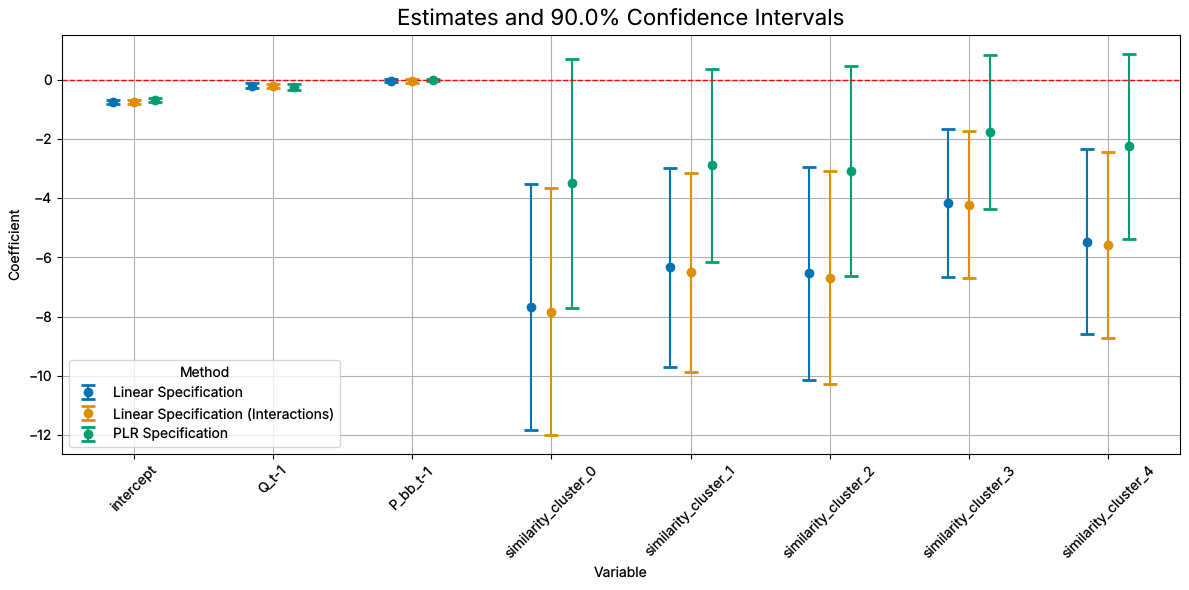

In [49]:
models = cate_summary_df["model"].unique()
variables = cate_summary_df["variable"].unique()
plt.figure(figsize=(12, 6))
bar_width = 0.15
x_positions = np.arange(len(variables))
for i, model in enumerate(models):
    df_model = cate_summary_df[cate_summary_df["model"] == model]
    if not df_model.empty:
        plt.errorbar(
            x_positions + i * bar_width,
            df_model["coef"],
            yerr=[
                df_model["coef"] - df_model["lower"],
                df_model["upper"] - df_model["coef"],
            ],
            fmt="o",
            label=model,
            capsize=5,
            capthick=2,
            ecolor=palette[i % len(palette)],
            color=palette[i % len(palette)],
            zorder=2,
        )
plt.xticks(x_positions + (len(models) - 1) * bar_width / 2, variables, rotation=45)
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.title(f"Estimates and {ci_level_name} Confidence Intervals", fontsize=16)
plt.xlabel("Variable")
plt.ylabel("Coefficient")
plt.legend(title="Method")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, f"cluster_and_level_cate_estimates.png"))
plt.show()

### $R^2$

In [50]:
alpha_x_lin = cate_models_polynomial["Linear Specification"].predict(df_basis)
alpha_x_lin_interactions = cate_models_polynomial[
    "Linear Specification (Interactions)"
].predict(df_basis)
alpha_x_plr = cate_models_polynomial["PLR Specification"].blp_model.predict(df_basis)


print("Linear Specification")
model_lin_emb = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[embeddings])).fit()
model_lin_sim = sm.OLS(
    alpha_x_lin, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_lvl = sm.OLS(alpha_x_lin, sm.add_constant(df_dynamic[lag_1_vars])).fit()

print("Variance explained by embeddings: ", model_lin_emb.rsquared)
print("Variance explained by similarities: ", model_lin_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_lvl.rsquared)

print("Linear Specification with interactions")
model_lin_interactions_emb = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[embeddings])
).fit()
model_lin_interactions_sim = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_lin_interactions_lvl = sm.OLS(
    alpha_x_lin_interactions, sm.add_constant(df_dynamic[lag_1_vars])
).fit()
print("Variance explained by embeddings: ", model_lin_interactions_emb.rsquared)
print("Variance explained by similarities: ", model_lin_interactions_sim.rsquared)
print("Variance explained by lagged variables: ", model_lin_interactions_lvl.rsquared)

print("PLR Specification")
model_plr_emb = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[embeddings])).fit()
model_plr_sim = sm.OLS(
    alpha_x_plr, sm.add_constant(df_dynamic[controls_similarities])
).fit()
model_plr_lvl = sm.OLS(alpha_x_plr, sm.add_constant(df_dynamic[lag_1_vars])).fit()
print("Variance explained by embeddings: ", model_plr_emb.rsquared)
print("Variance explained by similarities: ", model_plr_sim.rsquared)
print("Variance explained by lagged variables: ", model_plr_lvl.rsquared)

Linear Specification


Variance explained by embeddings:  0.6997919226023829
Variance explained by similarities:  0.6091055965679928
Variance explained by lagged variables:  0.5614053529638436
Linear Specification with interactions


Variance explained by embeddings:  0.6983932431170929
Variance explained by similarities:  0.6067070055263921
Variance explained by lagged variables:  0.5559346803102658
PLR Specification


Variance explained by embeddings:  0.5331535985102551
Variance explained by similarities:  0.39553497237431035
Variance explained by lagged variables:  0.7877835238924951


## $\Chi^2$ Test

In [51]:
# select index with cluster similarity
cluster_treatment_ids = [
    i for i, variable in enumerate(df_basis.columns) if "similarity_cluster" in variable
]
cluster_treatment_ids

[3, 4, 5, 6, 7]

In [52]:
lin_p_val = chi2_test(
    cate_models_polynomial["Linear Specification"], cluster_treatment_ids
)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], cluster_treatment_ids
)
tab_dml_p_val = chi2_test(
    cate_models_polynomial["PLR Specification"], cluster_treatment_ids
)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 0.0003857305747788642 (sample size: 38041)
Linear Specification (Interactions) p-value: 0.00020170606858005424 (sample size: 38041)
PLR Specification p-value: 0.016245615997178997 (sample size: 38041)


In [53]:
het_ids = [1, 2, 3, 4, 5, 6, 7]

lin_p_val = chi2_test(cate_models_polynomial["Linear Specification"], het_ids)
lin_interactions_p_val = chi2_test(
    cate_models_polynomial["Linear Specification (Interactions)"], het_ids
)
tab_dml_p_val = chi2_test(cate_models_polynomial["PLR Specification"], het_ids)

print(f"Linear Specification p-value: {lin_p_val} (sample size: {len(df_dynamic)})")
print(
    f"Linear Specification (Interactions) p-value: {lin_interactions_p_val} (sample size: {len(df_dynamic)})"
)
print(f"PLR Specification p-value: {tab_dml_p_val} (sample size: {len(df_dynamic)})")

Linear Specification p-value: 3.1336337968923544e-09 (sample size: 38041)
Linear Specification (Interactions) p-value: 7.833236281840072e-10 (sample size: 38041)
PLR Specification p-value: 1.1587608650387438e-10 (sample size: 38041)


## Sorted Effects

In [54]:
treatment_ids = [0, 1, 2] + cluster_treatment_ids
df_basis_sorted = df_basis.iloc[:, treatment_ids]  # .join(df_dynamic[["ASIN", "date"]])

In [55]:
df_basis_sorted

,intercept,Q_t-1,P_bb_t-1,similarity_cluster_0,similarity_cluster_1,similarity_cluster_2,similarity_cluster_3,similarity_cluster_4
0,1.0,0.305280,0.463601,0.023542,-0.110367,-0.002070,-0.130440,0.155107
1,1.0,0.272505,0.653600,0.023542,-0.110367,-0.002070,-0.130440,0.155107
2,1.0,0.036240,0.687961,0.023542,-0.110367,-0.002070,-0.130440,0.155107
3,1.0,0.025283,0.636881,0.023542,-0.110367,-0.002070,-0.130440,0.155107
4,1.0,-0.051370,0.556816,0.023542,-0.110367,-0.002070,-0.130440,0.155107
...,...,...,...,...,...,...,...,...
38036,1.0,0.009068,0.478593,-0.360735,0.108230,0.007841,0.421237,-0.000925
38037,1.0,-0.393270,-0.753352,0.058969,-0.112106,-0.017681,0.054582,0.014696
38038,1.0,-0.277916,-0.753352,0.046146,-0.123342,-0.011431,0.064414,0.025396
38039,1.0,1.267533,-1.535804,-0.092151,0.691463,-0.508637,0.276285,-0.219466


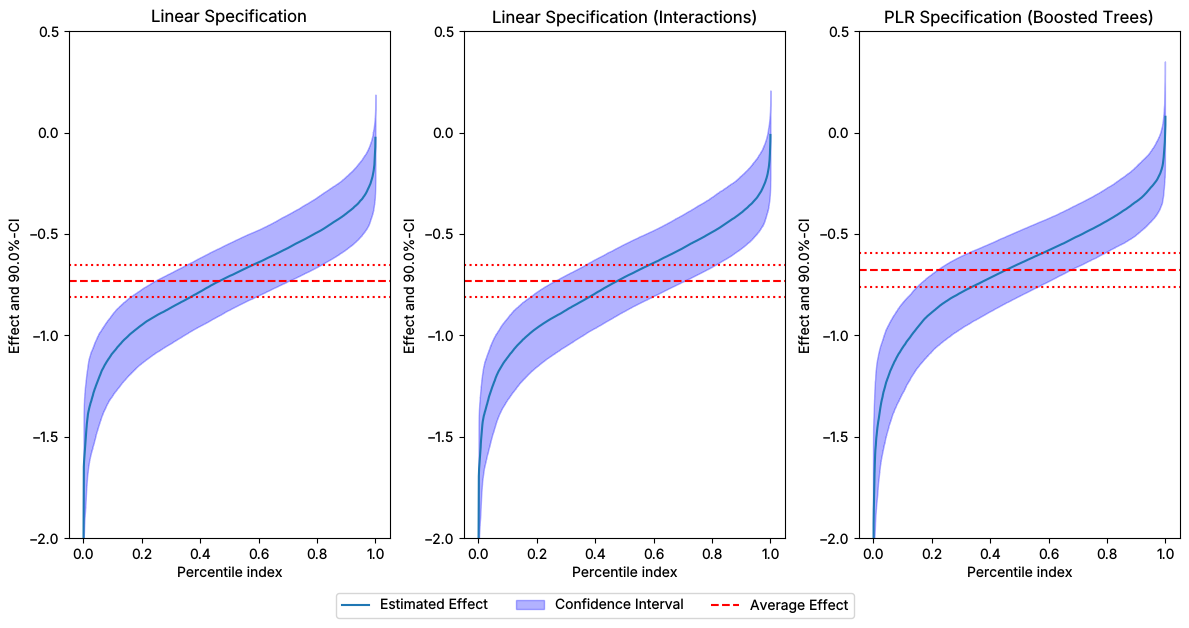

In [56]:
uniform_ci = False

plt.rcParams["figure.figsize"] = (
    15.0,
    7.5,
)  # Adjusted the figure size for side-by-side plots
# Determine the number of models to plot
num_plots = 1
# Create subplots with cate_vars as rows and models as columns
fig, axs = plt.subplots(nrows=num_plots, ncols=3, figsize=(12, 6 * num_plots))
# If there's only one model, axs won't be a list, so wrap it in a list
if num_plots == 1:
    axs = np.array([axs, axs])  # Create a 2-column array


# Linear model
df_lin_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_lin_ci_pointwise_sorted = df_lin_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_lin_ci_uniform = predict_cate(
    cate_models_polynomial["Linear Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_lin_ci_uniform_sorted = df_lin_ci_uniform.apply(
    lambda x: x.sort_values().values, axis=0
)
lm_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
lm_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# Tabular DML model
df_tab_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_tab_dml_ci_pointwise_sorted = df_tab_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_tab_dml_ci_joint = predict_cate(
    cate_models_polynomial["Linear Specification (Interactions)"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_tab_dml_ci_joint_sorted = df_tab_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)

tab_dml_intercept = cate_models_polynomial["Linear Specification"].params["intercept"]
tab_dml_intercept_ci = (
    cate_models_polynomial["Linear Specification"].conf_int().loc["intercept"]
)

# PLR Model
df_deep_dml_ci_pointwise = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
)
df_deep_dml_ci_pointwise_sorted = df_deep_dml_ci_pointwise.apply(
    lambda x: x.sort_values().values, axis=0
)
df_deep_dml_ci_joint = predict_cate(
    cate_models_polynomial["PLR Specification"],
    df_basis_sorted,
    treatment_ids=treatment_ids,
    level=confidence_level,
    joint=True,
)
df_deep_dml_ci_joint_sorted = df_deep_dml_ci_joint.apply(
    lambda x: x.sort_values().values, axis=0
)
deep_dml_intercept = cate_models_polynomial["PLR Specification"].blp_model.params[
    "intercept"
]
deep_dml_intercept_ci = (
    cate_models_polynomial["PLR Specification"].blp_model.conf_int().loc["intercept"]
)

# Calculate the y-axis limits for this row
y_min = min(
    df_lin_ci_pointwise[ci_names[0]].min(),
    df_lin_ci_uniform[ci_names[0]].min(),
    df_tab_dml_ci_pointwise[ci_names[0]].min(),
    df_tab_dml_ci_joint[ci_names[0]].min(),
    df_deep_dml_ci_pointwise[ci_names[0]].min(),
    df_deep_dml_ci_joint[ci_names[0]].min(),
)
y_max = max(
    df_lin_ci_pointwise[ci_names[1]].max(),
    df_lin_ci_uniform[ci_names[1]].max(),
    df_tab_dml_ci_pointwise[ci_names[1]].max(),
    df_tab_dml_ci_joint[ci_names[1]].max(),
    df_deep_dml_ci_pointwise[ci_names[1]].max(),
    df_deep_dml_ci_joint[ci_names[1]].max(),
)

# further adjust y-axis limits
y_min = max(y_min, -2)
y_max = min(y_max, 0.5)
percentiles_idx = np.linspace(0, 1, df_dynamic.shape[0])
percentiles_idx_full = np.linspace(0, 1, df_dynamic.shape[0])
# Plot on the first column
i = 0
ax0 = axs[i, 0]
ax0.plot(
    percentiles_idx_full, df_lin_ci_pointwise_sorted["effect"], label="Estimated Effect"
)
ax0.fill_between(
    percentiles_idx_full,
    df_lin_ci_pointwise_sorted[ci_names[0]],
    df_lin_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax0.fill_between(
        percentiles_idx_full,
        df_lin_ci_uniform_sorted[ci_names[0]],
        df_lin_ci_uniform_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax0.axhline(y=lm_intercept, color="r", linestyle="--", label="ATE")
ax0.axhline(y=lm_intercept_ci[0], color="r", linestyle="dotted")
ax0.axhline(y=lm_intercept_ci[1], color="r", linestyle="dotted")
ax0.set_title("Linear Specification")
ax0.set_xlabel("Percentile index")
ax0.set_ylabel(f"Effect and {ci_level_name}-CI")
ax0.set_ylim(y_min, y_max)
ax1 = axs[i, 1]
ax1.plot(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax1.fill_between(
    percentiles_idx_full,
    df_tab_dml_ci_pointwise_sorted[ci_names[0]],
    df_tab_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax1.fill_between(
        percentiles_idx_full,
        df_tab_dml_ci_joint_sorted[ci_names[0]],
        df_tab_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax1.axhline(y=tab_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax1.axhline(y=tab_dml_intercept_ci[0], color="r", linestyle="dotted")
ax1.axhline(y=tab_dml_intercept_ci[1], color="r", linestyle="dotted")
ax1.set_title("Linear Specification (Interactions)")
ax1.set_xlabel("Percentile index")
ax1.set_ylabel(f"Effect and {ci_level_name}-CI")
ax1.set_ylim(y_min, y_max)

ax2 = axs[i, 2]
ax2.plot(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted["effect"],
    label="Estimated Effect",
)
ax2.fill_between(
    percentiles_idx_full,
    df_deep_dml_ci_pointwise_sorted[ci_names[0]],
    df_deep_dml_ci_pointwise_sorted[ci_names[1]],
    color="b",
    alpha=0.3,
    label="Confidence Interval",
)
if uniform_ci:
    ax2.fill_between(
        percentiles_idx_full,
        df_deep_dml_ci_joint_sorted[ci_names[0]],
        df_deep_dml_ci_joint_sorted[ci_names[1]],
        color="b",
        alpha=0.1,
        label="Uniform Confidence Interval",
    )
ax2.axhline(y=deep_dml_intercept, color="r", linestyle="--", label="Average Effect")
ax2.axhline(y=deep_dml_intercept_ci[0], color="r", linestyle="dotted")
ax2.axhline(y=deep_dml_intercept_ci[1], color="r", linestyle="dotted")

ax2.set_title("PLR Specification (Boosted Trees)")
ax2.set_xlabel("Percentile index")
ax2.set_ylabel(f"Effect and {ci_level_name}-CI")
ax2.set_ylim(y_min, y_max)

# Create a single legend for all plots and place it at the lower center
handles, labels = axs[
    -1, 1 
].get_legend_handles_labels()  # Collect handles and labels from the last subplot
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, -0.05), ncol=4)
# Adjust layout to make space for the legend
plt.tight_layout(rect=[0, 0.0, 1, 1])  # Leave space at the bottom for the legend

# Save the figure with tight bounding box to include the legend
plt.savefig(os.path.join(output_dir, "cluster_sorted_effects.png"), bbox_inches="tight")
plt.show()

In [57]:
quantiles = np.arange(start=0.01, stop=1, step=0.01)
m = len(quantiles)
pes = df_tab_dml_ci_pointwise["effect"]
spes = df_tab_dml_ci_pointwise["effect"].quantile(quantiles).values
spes

array([-1.49036492, -1.38747112, -1.33603214, -1.2835121 , -1.24358967,
       -1.20442985, -1.17321476, -1.14826749, -1.12634777, -1.10769052,
       -1.08833998, -1.07069328, -1.05384342, -1.03816869, -1.0239846 ,
       -1.01015982, -0.9973905 , -0.98539985, -0.97336008, -0.96260495,
       -0.95284134, -0.94323312, -0.93355602, -0.92481267, -0.91646248,
       -0.90814923, -0.90001201, -0.89258365, -0.88381132, -0.87530719,
       -0.86635013, -0.85818801, -0.85064902, -0.84234042, -0.83429482,
       -0.82627215, -0.81813044, -0.81012436, -0.80115282, -0.79270605,
       -0.78403483, -0.77583606, -0.7669264 , -0.75874742, -0.75116471,
       -0.74281651, -0.73519774, -0.72769681, -0.72017574, -0.71243976,
       -0.70524141, -0.69821674, -0.691297  , -0.68397574, -0.67657574,
       -0.66941591, -0.66226282, -0.65544297, -0.6485548 , -0.64205899,
       -0.6350702 , -0.62791916, -0.62039072, -0.61328671, -0.60620359,
       -0.59916781, -0.59195706, -0.58438636, -0.57708803, -0.56

# Sensitivity Analysis

Sensitivity analysis for ATE with PLM model.

In [58]:
plr_obj.sensitivity_analysis(
    cf_y=0.03,
    cf_d=0.03,
    rho=1.0,
    level=0.9,
    null_hypothesis=0.0
)
print(plr_obj.sensitivity_summary)

================== Sensitivity Analysis ==================

------------------ Scenario          ------------------
Significance Level: level=0.9
Sensitivity parameters: cf_y=0.03; cf_d=0.03, rho=1.0

------------------ Bounds with CI    ------------------
        CI lower  theta lower     theta  theta upper  CI upper
P_bb_t -0.819727    -0.762874 -0.635808    -0.508742 -0.442444

------------------ Robustness Values ------------------
        H_0     RV (%)   RVa (%)
P_bb_t  0.0  14.124339  12.34939


In [59]:
sigma_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["sigma2"]
sigma_s = tab_dml_obj_embeddings.sensitivity_elements["sigma2"]

nu_l = tab_dml_obj_embeddings_add_controls.sensitivity_elements["nu2"]
nu_s = tab_dml_obj_embeddings.sensitivity_elements["nu2"]

delta_theta = tab_dml_obj_embeddings_add_controls.coef - tab_dml_obj_embeddings.coef

rho_hat = np.abs(delta_theta) / (np.sqrt(sigma_s - sigma_l) * np.sqrt(nu_l - nu_s)).squeeze()

print(f"Implied rho: {rho_hat}")

Implied rho: [0.08439119]


In [60]:
r2_scores_l = tab_dml_obj_embeddings_add_controls.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_l['ml_l'][0, 0]} R2 Treatment: {r2_scores_l['ml_m'][0, 0]}\n"
)

r2_y_l = r2_scores_l["ml_l"][0, 0]
r2_d_l = r2_scores_l["ml_m"][0, 0]


r2_scores_s = tab_dml_obj_embeddings.evaluate_learners(metric=r2)
print(
    f"R2 Outcome: {r2_scores_s['ml_l'][0, 0]} R2 Treatment: {r2_scores_s['ml_m'][0, 0]}\n"
)

r2_y_s = r2_scores_s["ml_l"][0, 0]
r2_d_s = r2_scores_s["ml_m"][0, 0]

R2 Outcome: 0.8984084698807858 R2 Treatment: 0.9742396270572924

R2 Outcome: 0.8723482427197335 R2 Treatment: 0.9721650210184282



In [61]:
partial_r2_y = (r2_y_l - r2_y_s) / (1 - r2_y_s)
partial_r2_d = (r2_d_l - r2_d_s) / (1 - r2_d_s)

print(f"Partial R2 Outcome: {partial_r2_y}")
print(f"Partial R2 Treatment: {partial_r2_d}")

Partial R2 Outcome: 0.2041509472042411
Partial R2 Treatment: 0.07453233718041312


In [62]:
# NEW CHECK

K = rho_hat * np.sqrt(partial_r2_y * partial_r2_d / (1 - partial_r2_d))
scaled_implied_RV = (-K**2 + K*np.sqrt(K**2 + 4)) / 2

print(scaled_implied_RV.round(4))

[0.0108]


In [63]:
# Check

np.sqrt(scaled_implied_RV * scaled_implied_RV / (1 - scaled_implied_RV))

array([0.01082093])

In [64]:
sensitivity_res = dict()

rho_vec = [1.0, 0.5, 0.2]
scenarios = [(0.01, 0.01), (0.025, 0.025), (0.05, 0.05)]

theta_lower = []
theta_upper = []
ci_lower = []   
ci_upper = []
R2_y = []
R2_d = []
rho_list = []

for rho in rho_vec:
    for cf_y, cf_d in scenarios:
        plr_obj.sensitivity_analysis(
            cf_y=cf_y,
            cf_d=cf_d,
            rho=rho,
            level=confidence_level,
            null_hypothesis=0.0
        )
        theta_lower.append(plr_obj.sensitivity_params["theta"]["lower"][0])
        theta_upper.append(plr_obj.sensitivity_params["theta"]["upper"][0])
        ci_lower.append(plr_obj.sensitivity_params["ci"]["lower"][0])
        ci_upper.append(plr_obj.sensitivity_params["ci"]["upper"][0])
        R2_y.append(cf_y)
        R2_d.append(cf_d)
        rho_list.append(rho)


In [65]:
df_sensitivity = pd.DataFrame({
    "theta": plr_obj.coef[0],
    "theta_lower": theta_lower,
    "theta_upper": theta_upper,
    "ci_lower": ci_lower,
    "ci_upper": ci_upper,
    "R2_y": R2_y,
    "R2_d": R2_d,
    "rho": rho_list,
})
df_sensitivity.head()

,theta,theta_lower,theta_upper,ci_lower,ci_upper,R2_y,R2_d,rho
0,-0.635808,-0.677734,-0.593883,-0.737502,-0.530986,0.010,0.010,1.0
1,-0.635808,-0.741425,-0.530192,-0.798985,-0.464770,0.025,0.025,1.0
2,-0.635808,-0.849803,-0.421814,-0.903992,-0.351846,0.050,0.050,1.0
3,-0.635808,-0.656771,-0.614846,-0.717300,-0.552752,0.010,0.010,0.5
4,-0.635808,-0.688617,-0.583000,-0.747997,-0.519680,0.025,0.025,0.5


In [66]:
scenario_names = ["mild", "medium", "strong"]

latex_args = {
    "index": False,
    "float_format": "%.3f",
    "column_format": "lcccccc",
    "escape": False,  # Allow LaTeX in column names
}

ci_lower_label = f"$[ {{{100*(1-confidence_level):.1f}}}\\% $"
ci_upper_label = f"${{{100*(confidence_level):.1f}}}\\% ]$"

for rho_val in rho_vec:
    df_rho = df_sensitivity[df_sensitivity["rho"] == rho_val].copy()
    # Add scenario column with names
    df_rho["Scenario ($R^2_Y$, $R^2_D$)"] = [
        f"{name} $({str(r2y).lstrip('0')}, {str(r2d).lstrip('0')})$"
        for name, r2y, r2d in zip(scenario_names, df_rho["R2_y"], df_rho["R2_d"])
    ]
    # Rename columns for LaTeX
    df_rho = df_rho.rename(
        columns={
            "theta": r"$\theta$",
            "theta_lower": r"$\theta_-$",
            "theta_upper": r"$\theta_+$",
            "ci_lower": ci_lower_label,
            "ci_upper": ci_upper_label,
        }
    )
    # Reorder columns as requested
    df_rho = df_rho[
        [
            "Scenario ($R^2_Y$, $R^2_D$)",
            ci_lower_label,
            r"$\theta_-$",
            r"$\theta$",
            r"$\theta_+$",
            ci_upper_label,
        ]
    ]
    caption = (
        f"Sensitivity analysis for $\\rho={rho_val}$: "
    )
    latex_str = df_rho.to_latex(
        caption=caption,
        label=f"tab:sensitivity_rho_{str(rho_val).replace('.', '')}",
        **latex_args,
    )
    # Insert \hline\hline after \begin{tabular} and replace \toprule/\bottomrule
    latex_str = latex_str.replace("\\toprule", "\\hline\\hline")
    latex_str = latex_str.replace("\\midrule", "\\midrule")
    latex_str = latex_str.replace("\\bottomrule", "\\hline\\hline")
    latex_str = latex_str.replace("\\begin{table}", "\\begin{table}[h]\n\\centering")
    print(latex_str)

\begin{table}[h]
\centering
\caption{Sensitivity analysis for $\rho=1.0$: }
\label{tab:sensitivity_rho_10}
\begin{tabular}{lcccccc}
\hline\hline
Scenario ($R^2_Y$, $R^2_D$) & $[ {10.0}\% $ & $\theta_-$ & $\theta$ & $\theta_+$ & ${90.0}\% ]$ \\
\midrule
mild $(.01, .01)$ & -0.738 & -0.678 & -0.636 & -0.594 & -0.531 \\
medium $(.025, .025)$ & -0.799 & -0.741 & -0.636 & -0.530 & -0.465 \\
strong $(.05, .05)$ & -0.904 & -0.850 & -0.636 & -0.422 & -0.352 \\
\hline\hline
\end{tabular}
\end{table}

\begin{table}[h]
\centering
\caption{Sensitivity analysis for $\rho=0.5$: }
\label{tab:sensitivity_rho_05}
\begin{tabular}{lcccccc}
\hline\hline
Scenario ($R^2_Y$, $R^2_D$) & $[ {10.0}\% $ & $\theta_-$ & $\theta$ & $\theta_+$ & ${90.0}\% ]$ \\
\midrule
mild $(.01, .01)$ & -0.717 & -0.657 & -0.636 & -0.615 & -0.553 \\
medium $(.025, .025)$ & -0.748 & -0.689 & -0.636 & -0.583 & -0.520 \\
strong $(.05, .05)$ & -0.800 & -0.743 & -0.636 & -0.529 & -0.463 \\
\hline\hline
\end{tabular}
\end{table}

\begin

# Export of Key Results

Collects the main estimates of this notebook in `output_dir` (used by `02_cluster_summary.ipynb` and `04_evaluation_comparison.ipynb`).

In [67]:
import json

key_results = {
    "data_dir": data_dir,
    "txt_only": txt_only,
    "emb_dim": emb_dim,
    "dataset": dataframe_name,
    "n_obs": int(len(df_dynamic)),
    "n_products": int(df_dynamic["ASIN"].nunique()),
}

# Linear models (ATE)
ci_linear_interactions["model"] = "Linear interactions"
df_linear = pd.concat([df_base, ci_linear_interactions], ignore_index=True)
df_linear.to_csv(os.path.join(output_dir, "linear_ate_estimates.csv"), index=False)

# PLR models (ATE) and learner R^2
plr_objects = {
    "plr_embeddings": tab_dml_obj_embeddings,
    "plr_add_controls": tab_dml_obj_add_controls,
    "plr_embeddings_add_controls": tab_dml_obj_embeddings_add_controls,
    "plr_sim_add_controls": tab_dml_obj_sim_add_controls,
    "plr_pca_add_controls": tab_dml_obj_pca_add_controls,
}
df_plr = df_averages.copy()
for model_name, obj in plr_objects.items():
    r2_scores = obj.evaluate_learners(metric=r2)
    df_plr.loc[df_plr["model"] == model_name, "std_err"] = obj.se[0]
    df_plr.loc[df_plr["model"] == model_name, "r2_outcome"] = r2_scores["ml_l"][0, 0]
    df_plr.loc[df_plr["model"] == model_name, "r2_treatment"] = r2_scores["ml_m"][0, 0]
df_plr.to_csv(os.path.join(output_dir, "plr_ate_estimates.csv"), index=False)
df_plr

,lower,upper,coef,model,std_err,r2_outcome,r2_treatment
0,-0.668176,-0.504611,-0.586393,plr_embeddings,0.049720,0.872348,0.972165
1,-0.757775,-0.622714,-0.690244,plr_add_controls,0.041056,0.899101,0.977486
2,-0.714491,-0.557126,-0.635808,plr_embeddings_add_controls,0.047835,0.898408,0.974240
3,-0.741722,-0.612248,-0.676985,plr_sim_add_controls,0.039357,0.899823,0.977075
4,-0.757284,-0.621943,-0.689613,plr_pca_add_controls,0.041141,0.901613,0.977336


In [68]:
# GATEs by most similar cluster
df_gates = gates_0_summ.copy()
group_sizes = groups.groupby(0).size()
group_sizes.index = "Group_" + group_sizes.index.astype(str)  # labels used by DoubleMLPLR.gate()
df_gates["n_obs"] = group_sizes.reindex(df_gates.index).values
assert df_gates["n_obs"].notna().all()
df_gates.to_csv(os.path.join(output_dir, "gate_estimates.csv"))

# CATE (best linear predictor) coefficients
cate_summary_df.to_csv(os.path.join(output_dir, "cate_estimates.csv"), index=False)

# Chi^2 tests
chi2_rows = []
for model_name, model in cate_models_polynomial.items():
    chi2_rows.append(
        {
            "model": model_name,
            "p_value_clusters": chi2_test(model, cluster_treatment_ids),
            "p_value_heterogeneity": chi2_test(model, het_ids),
        }
    )
df_chi2 = pd.DataFrame(chi2_rows)
df_chi2.to_csv(os.path.join(output_dir, "chi2_tests.csv"), index=False)

# Variance of the CATE explained by embeddings, similarities and lagged variables
df_var_explained = pd.DataFrame(
    {
        "Linear Specification": [model_lin_emb.rsquared, model_lin_sim.rsquared, model_lin_lvl.rsquared],
        "Linear Specification (Interactions)": [
            model_lin_interactions_emb.rsquared,
            model_lin_interactions_sim.rsquared,
            model_lin_interactions_lvl.rsquared,
        ],
        "PLR Specification": [model_plr_emb.rsquared, model_plr_sim.rsquared, model_plr_lvl.rsquared],
    },
    index=["embeddings", "similarities", "lagged variables"],
)
df_var_explained.to_csv(os.path.join(output_dir, "cate_variance_explained.csv"))
df_chi2

,model,p_value_clusters,p_value_heterogeneity
0,Linear Specification,0.000386,3.133634e-09
1,Linear Specification (Interactions),0.000202,7.833236e-10
2,PLR Specification,0.016246,1.158761e-10


In [69]:
# Per-observation CATEs (as in ../output/04_evaluation/sorted_effects.csv)
df_sorted_effects = df_dynamic[["ASIN", "date"]].copy()
df_sorted_effects["SortEff_lin"] = df_lin_ci_pointwise["effect"].values
df_sorted_effects["SortEff_tab_dml"] = df_tab_dml_ci_pointwise["effect"].values
df_sorted_effects["SortEff_deep_dml"] = df_deep_dml_ci_pointwise["effect"].values
df_sorted_effects.to_csv(os.path.join(output_dir, "sorted_effects.csv"), index=False)

# Sensitivity analysis
df_sensitivity.to_csv(os.path.join(output_dir, "sensitivity_analysis.csv"), index=False)
plr_obj.sensitivity_analysis(cf_y=0.03, cf_d=0.03, rho=1.0, level=0.9, null_hypothesis=0.0)
key_results["sensitivity"] = {
    "theta": float(plr_obj.coef[0]),
    "theta_lower_cf003": float(plr_obj.sensitivity_params["theta"]["lower"][0]),
    "theta_upper_cf003": float(plr_obj.sensitivity_params["theta"]["upper"][0]),
    "ci_lower_cf003": float(plr_obj.sensitivity_params["ci"]["lower"][0]),
    "ci_upper_cf003": float(plr_obj.sensitivity_params["ci"]["upper"][0]),
    "rv": float(plr_obj.sensitivity_params["rv"][0]),
    "rva": float(plr_obj.sensitivity_params["rva"][0]),
    "implied_rho": float(np.squeeze(rho_hat)),
    "partial_r2_outcome": float(partial_r2_y),
    "partial_r2_treatment": float(partial_r2_d),
    "scaled_implied_rv": float(np.squeeze(scaled_implied_RV)),
}
key_results["sorted_effects_quantiles"] = {
    col: df_sorted_effects[col].quantile([0.05, 0.25, 0.5, 0.75, 0.95]).round(6).tolist()
    for col in ["SortEff_lin", "SortEff_tab_dml", "SortEff_deep_dml"]
}
with open(os.path.join(output_dir, "key_results.json"), "w") as f:
    json.dump(key_results, f, indent=2)
print(json.dumps(key_results, indent=2))

{
  "data_dir": "../data",
  "txt_only": true,
  "emb_dim": 256,
  "dataset": "dataset_txt_only_True_embeddings_True",
  "n_obs": 38041,
  "n_products": 3708,
  "sensitivity": {
    "theta": -0.6358084201097898,
    "theta_lower_cf003": -0.7628744816141532,
    "theta_upper_cf003": -0.5087423586054264,
    "ci_lower_cf003": -0.819726632205747,
    "ci_upper_cf003": -0.44244449301514804,
    "rv": 0.14124338776345788,
    "rva": 0.12349389871192713,
    "implied_rho": 0.08439118944013742,
    "partial_r2_outcome": 0.2041509472042411,
    "partial_r2_treatment": 0.07453233718041312,
    "scaled_implied_rv": 0.010762541274643
  },
  "sorted_effects_quantiles": {
    "SortEff_lin": [
      -1.219693,
      -0.901188,
      -0.706658,
      -0.530674,
      -0.333347
    ],
    "SortEff_tab_dml": [
      -1.24359,
      -0.916462,
      -0.71244,
      -0.530463,
      -0.326369
    ],
    "SortEff_deep_dml": [
      -1.204821,
      -0.830511,
      -0.645488,
      -0.473899,
      -0.269